In [ ]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(4) * 100)

print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
Duplicate customerIDs: 0


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
converted = pd.to_numeric(df["TotalCharges"], errors="coerce")

bad = df[converted.isna()]
print("Rows that failed conversion:", len(bad))
print(bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

print("What the bad values actually look like:", bad["TotalCharges"].map(repr).unique())

Rows that failed conversion: 11
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No
What the bad values actually look like: <StringArray>
['' '']
Length: 1, dtype: str


In [7]:
assert (bad["tenure"] == 0).all(), "Theory wrong: some blank rows have tenure > 0"

df["TotalCharges"] = converted.fillna(0)

print(df["TotalCharges"].dtype)
print("Missing values left:", df.isna().sum().sum())

float64
Missing values left: 0


In [8]:
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print("Churn rate from flag:", round(df["churn_flag"].mean() * 100, 2), "%")
print("Duplicates:", df.duplicated().sum())
df.dtypes

Churn rate from flag: 26.54 %
Duplicates: 0


customerID              str
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
churn_flag            int64
dtype: object

tenure: normal range (-60.0 to 124.0), outliers found: 0
MonthlyCharges: normal range (-46.0 to 171.4), outliers found: 0
TotalCharges: normal range (-4683.5 to 8868.7), outliers found: 0


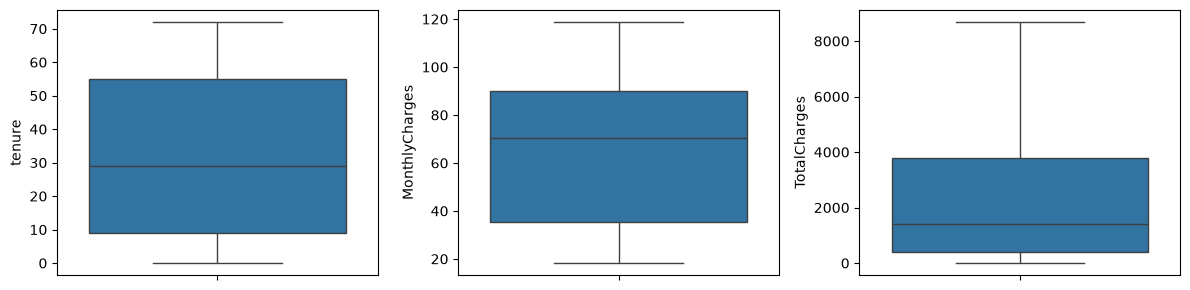

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: normal range ({low:.1f} to {high:.1f}), outliers found: {n_out}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(y=df[col], ax=ax)
plt.tight_layout()
plt.show()

In [10]:
df.to_csv("../data/telco_clean.csv", index=False)
print("Saved", df.shape)

Saved (7043, 22)


In [11]:
import numpy as np

df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, np.inf],
    labels=["0-12", "13-24", "25-48", "49+"],
)

sns.set_theme(style="whitegrid")
baseline = df["churn_flag"].mean() * 100

def churn_by(col, filename=None, keep_order=False, plot=True):
    """Churn rate and customer count per category of `col`; optionally draw and save a bar chart."""
    out = df.groupby(col, observed=True)["churn_flag"].agg(customers="count", churn_rate="mean")
    out["churn_rate"] = (out["churn_rate"] * 100).round(2)
    if not keep_order:
        out = out.sort_values("churn_rate", ascending=False)

    if plot:
        fig, ax = plt.subplots(figsize=(7, 4))
        bars = ax.bar(out.index.astype(str), out["churn_rate"])
        ax.bar_label(bars, fmt="%.1f%%")
        ax.axhline(baseline, color="red", linestyle="--", label=f"Overall: {baseline:.1f}%")
        ax.set_ylabel("Churn rate (%)")
        ax.set_title(f"Churn rate by {col}")
        ax.legend()
        plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
        if filename:
            plt.savefig(f"../images/{filename}", dpi=150, bbox_inches="tight")  # saved for the README
        plt.show()
    return out

df["tenure_bucket"].value_counts().sort_index()

tenure_bucket
0-12     2186
13-24    1024
25-48    1594
49+      2239
Name: count, dtype: int64

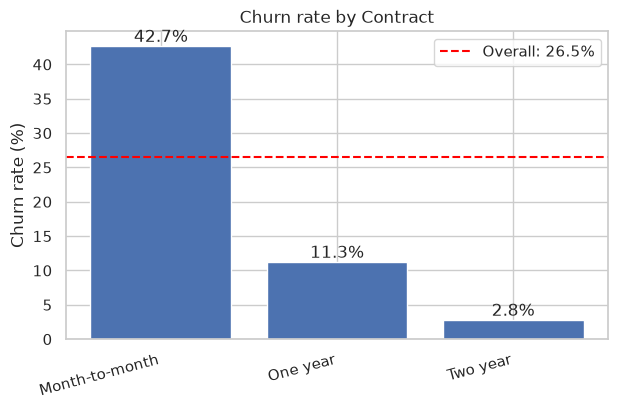

,customers,churn_rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


In [12]:
churn_by("Contract", "churn_by_contract.png")

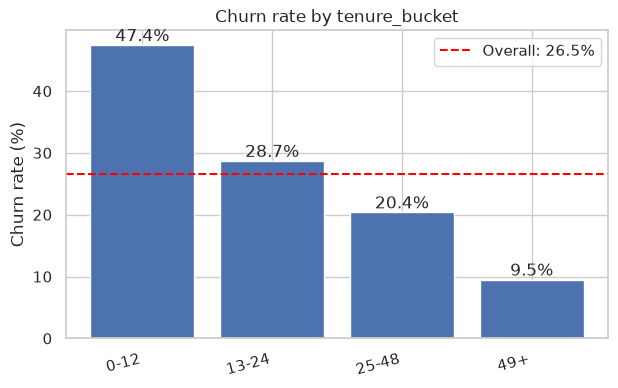

,customers,churn_rate
tenure_bucket,,
0-12,2186,47.44
13-24,1024,28.71
25-48,1594,20.39
49+,2239,9.51


In [13]:
churn_by("tenure_bucket", "churn_by_tenure.png", keep_order=True)

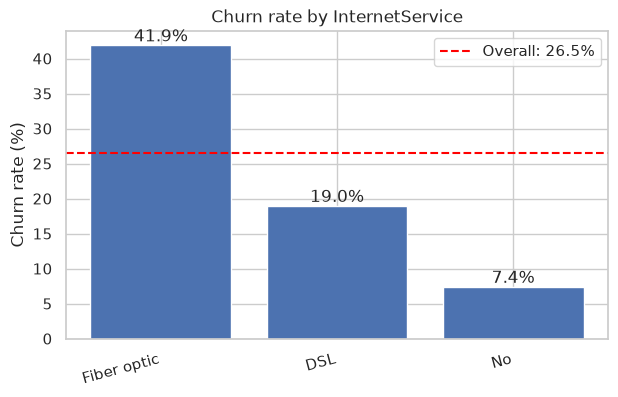

                 customers  churn_rate
InternetService                       
Fiber optic           3096       41.89
DSL                   2421       18.96
No                    1526        7.40


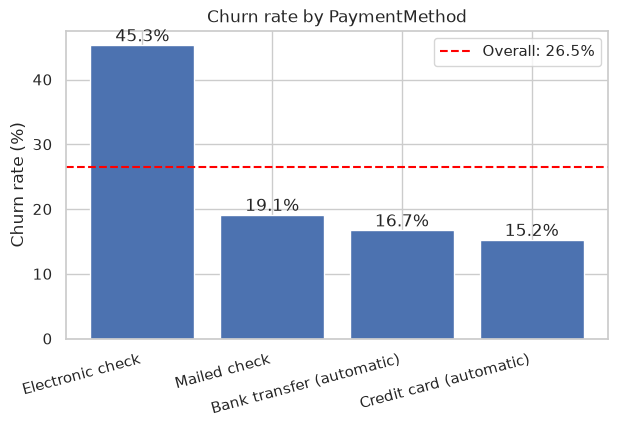

                           customers  churn_rate
PaymentMethod                                   
Electronic check                2365       45.29
Mailed check                    1612       19.11
Bank transfer (automatic)       1544       16.71
Credit card (automatic)         1522       15.24


In [14]:
print(churn_by("InternetService", "churn_by_internet.png"))
print(churn_by("PaymentMethod", "churn_by_payment.png"))

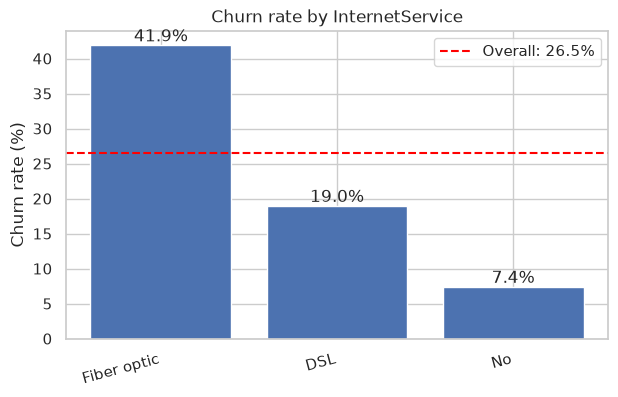

                 customers  churn_rate
InternetService                       
Fiber optic           3096       41.89
DSL                   2421       18.96
No                    1526        7.40


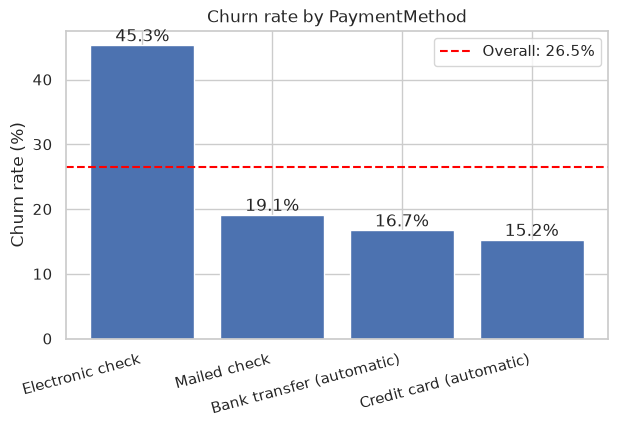

                           customers  churn_rate
PaymentMethod                                   
Electronic check                2365       45.29
Mailed check                    1612       19.11
Bank transfer (automatic)       1544       16.71
Credit card (automatic)         1522       15.24


In [15]:
print(churn_by("InternetService", "churn_by_internet.png"))
print(churn_by("PaymentMethod", "churn_by_payment.png"))

In [16]:
for col in ["SeniorCitizen", "gender", "Partner", "Dependents",
            "PaperlessBilling", "OnlineSecurity", "TechSupport"]:
    print(f"--- {col} ---")
    print(churn_by(col, plot=False), "\n")

--- SeniorCitizen ---
               customers  churn_rate
SeniorCitizen                       
Yes                 1142       41.68
No                  5901       23.61 

--- gender ---
        customers  churn_rate
gender                       
Female       3488       26.92
Male         3555       26.16 

--- Partner ---
         customers  churn_rate
Partner                       
No            3641       32.96
Yes           3402       19.66 

--- Dependents ---
            customers  churn_rate
Dependents                       
No               4933       31.28
Yes              2110       15.45 

--- PaperlessBilling ---
                  customers  churn_rate
PaperlessBilling                       
Yes                    4171       33.57
No                     2872       16.33 

--- OnlineSecurity ---
                     customers  churn_rate
OnlineSecurity                            
No                        3498       41.77
Yes                       2019       14.61
No interne

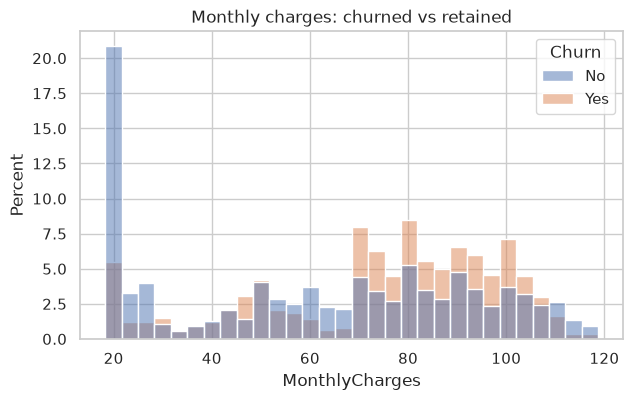

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


In [17]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30,
             stat="percent", common_norm=False, ax=ax)
ax.set_title("Monthly charges: churned vs retained")
plt.savefig("../images/monthly_charges_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

Contract
Month-to-month    88.55
One year           8.88
Two year           2.57
Name: proportion, dtype: float64
Contract       Month-to-month  One year  Two year
tenure_bucket                                    
0-12                    51.35     10.48      0.00
13-24                   37.72      8.12      0.00
25-48                   32.92     10.62      2.19
49+                     26.02     12.93      3.33
Contract       Month-to-month  One year  Two year
tenure_bucket                                    
0-12                     1994       124        68
13-24                     737       197        90
25-48                     802       518       274
49+                       342       634      1263


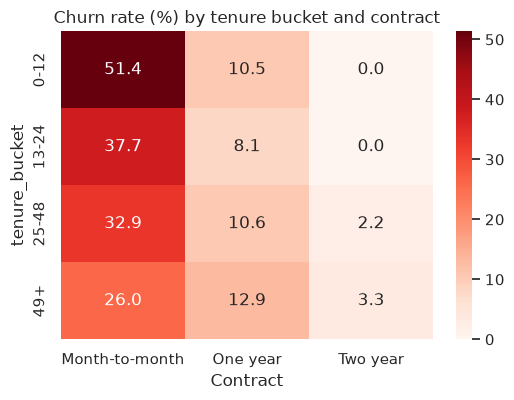

In [18]:
churners = df[df["churn_flag"] == 1]
print((churners["Contract"].value_counts(normalize=True) * 100).round(2))

pivot = df.pivot_table(index="tenure_bucket", columns="Contract",
                       values="churn_flag", aggfunc="mean", observed=True) * 100
print(pivot.round(2))

print(df.pivot_table(index="tenure_bucket", columns="Contract",
                     values="churn_flag", aggfunc="count", observed=True))

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=ax)
ax.set_title("Churn rate (%) by tenure bucket and contract")
plt.savefig("../images/churn_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()